# Линейная алгебра для ML — домашнее задание

**Автор:** _имя_ · **Модуль:** математика для ML, тема 1

Как устроено каждое задание:

1. **Вручную** — расчёт с числами в markdown: формула → подстановка → ответ.
2. **Код** — свои функции на чистом Python, без готовых функций NumPy.
3. **Проверка NumPy** — тот же расчёт через NumPy и сравнение через `check()`.
4. **Визуализация** — там, где её просят.
5. **Вывод** — 2–4 предложения своими словами.

In [2]:
import math

import numpy as np
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


## 0. Функции

Здесь живут функции, которые используются в нескольких заданиях (требование задания 6). Добавляй их по мере необходимости: первые появятся в задании 1.

In [7]:
def dot(a, b):
    total = 0
    for x, y in zip(a, b):
        total += x * y
    return total


## 1. Векторы

Векторы $a = [2, 1]$ и $b = [1, 3]$.

- найди $a + b$, $a - b$, $2a - 3b$ и скалярное произведение $a \cdot b$
- вычисли длину каждого вектора и угол между ними
- проверь, являются ли векторы линейно независимыми
- изобрази $a$, $b$ и $a + b$ на одной координатной плоскости
- объясни, что означает скалярное произведение с точки зрения направления векторов

In [5]:
a = np.array([2, 1])
b = np.array([1, 3])

In [ ]:
print(dot(a, b), np.dot(a, b))
# print(dot([1, 0], [-1, 0]))

5 5
-1


### 1.1 Операции — вручную

_Распиши: формула → подстановка чисел → ответ. Например:_ $a + b = [2 + 1,\ 1 + 3] = [\,?,\ ?\,]$
Векторы $a = [2, 1]$ и $b = [1, 3]$.

a + b = [2 + 1, 1 + 3] = [3, 4]
a − b = [2 - 1, 1 - 3] = [1, -2]
2a − 3b = [4 - 3, 2 - 9] = [1, -7]
a · b = 2 * 1 + 1 * 3 = 2 + 3 = 5

In [13]:
print("a + b   =", a + b)
print("a - b   =", a - b)
print("2a - 3b =", 2 * a - 3 * b)
print("a · b   =", dot(a, b), "| NumPy:", a @ b)

a + b   = [3 4]
a - b   = [ 1 -2]
2a - 3b = [ 1 -7]
a · b   = 5 | NumPy: 5


### 1.2 Длины и угол — вручную

_Формулы:_ $\|a\| = \sqrt{a \cdot a}$, $\quad \cos\theta = \dfrac{a \cdot b}{\|a\|\,\|b\|}$

_Подставь числа:_

|a| = √(a·a) = √(2·2 + 1·1) = √5 ≈ 2,24
|b| = √(1 * 1 + 3 * 3) = √10 ≈ 3,16
cos θ = a·b / (|a|·|b|) = 5 / (√5 · √10) = 5 / √50 ≈ 5 / 7,07 ≈ 0,707
θ = arccos(0,707) = 45°

In [19]:
def norm(a):
    return math.sqrt(dot(a, a))         # длина = корень из dot вектора на самого себя

def angle_deg(a, b):
    cos = dot(a, b) / (norm(a) * norm(b))       # формула косинуса из пункта А
    return math.degrees(math.acos(cos))

print("|a| =", norm(a), "| NumPy:", np.linalg.norm(a))
print("|b| =", norm(b), "| NumPy:", np.linalg.norm(b))
print("угол =", angle_deg(a, b))

|a| = 2.23606797749979 | NumPy: 2.23606797749979
|b| = 3.1622776601683795 | NumPy: 3.1622776601683795
угол = 45.00000000000001


### 1.3 Линейная независимость — вручную

_Два вектора на плоскости независимы, если не лежат на одной прямой. Проверка: определитель матрицы, где $a$ и $b$ — столбцы, не равен нулю._

матрица: | 2  1 |
         | 1  3 |

det = 2·3 − 1·1 = 5
det ≠ 0 → векторы линейно независимы то есть не лежат на одной прямой

In [20]:
# TODO: свой определитель 2×2 и проверка через np.linalg.det или np.linalg.matrix_rank
def det2(a, b):
    return a[0] * b[1] - a[1] * b[0]     # a[0] — первая координата a, a[1] — вторая

M = np.column_stack([a, b])      # склеивает a и b в матрицу столбцами
print("det вручную:", det2(a, b), "| NumPy:", np.linalg.det(M))
print("ранг:", np.linalg.matrix_rank(M))

det вручную: 5 | NumPy: 5.000000000000001
ранг: 2


### 1.4 Рисунок

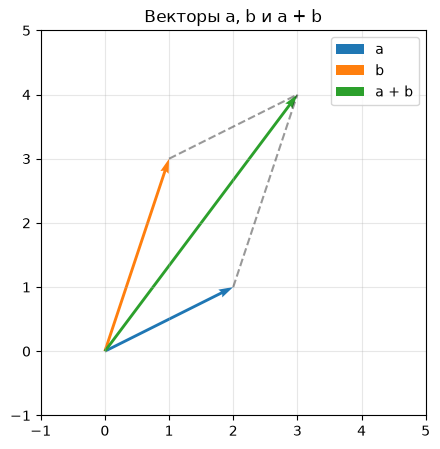

In [21]:
# TODO: a, b и a + b стрелками из начала координат (plt.quiver)
# подписи векторов, сетка, одинаковый масштаб осей

s = a + b                                   # вектор a + b

fig, ax = plt.subplots(figsize=(5, 5))

# стрелка из точки (0, 0) в точку (x, y)
ax.quiver(0, 0, a[0], a[1], angles='xy', scale_units='xy', scale=1, color='tab:blue', label='a')
ax.quiver(0, 0, b[0], b[1], angles='xy', scale_units='xy', scale=1, color='tab:orange', label='b')
ax.quiver(0, 0, a[0] + b[0], a[1] + b[1], angles='xy', scale_units='xy', scale=1, color='tab:green', label='a + b')

# пунктир — правило параллелограмма
ax.plot([a[0], s[0]], [a[1], s[1]], 'k--', alpha=0.4)
ax.plot([b[0], s[0]], [b[1], s[1]], 'k--', alpha=0.4)

ax.set_xlim(-1, 5)
ax.set_ylim(-1, 5)
ax.set_aspect('equal')                      # одинаковый масштаб осей
ax.grid(alpha=0.3)
ax.legend()
ax.set_title('Векторы a, b и a + b')
plt.show()

### Мой вывод

_Ответь своими словами:_
- что значит, что $a \cdot b > 0$? Когда скалярное произведение равно нулю, а когда отрицательное?
- как скалярное произведение связано с углом между векторами?
- что даёт то, что $a$ и $b$ линейно независимы?

1. Скалярное произведение это число, по которому понятно смотрят ли две стрелки в одну сторону. У нас вышло 5 и это больше нуля, значит примерно в одну. При нуле стрелки были бы под прямым углом, при минусе смотрели бы в разные стороны.

2. Угол между ними 45°, это меньше 90°, косинус положительный, поэтому и скалярное произведение положительное 

3. Векторы не лежат на одной линии  и один нельзя получить из другого растяжением. Это и есть независимость. Определитель 5, а не ноль  и на графике параллелограмм не сплющен.

## 2. Матрицы и линейные преобразования

Матрицы $A = \begin{pmatrix} 2 & 1 \\ 1 & 3 \end{pmatrix}$ и $B = \begin{pmatrix} 1 & 2 \\ 0 & 1 \end{pmatrix}$.

- вычисли $A + B$, $AB$ и $BA$ и объясни, почему $AB$ и $BA$ могут отличаться
- примени обе матрицы к векторам $[1, 0]$ и $[0, 1]$
- нарисуй исходные и преобразованные базисные векторы
- опиши своими словами, как каждая матрица меняет пространство

_Разберём после задания 1._

In [22]:
# задание 2
print(det2(a, np.array([4, 2])))

0


## 3. Определитель, обратная матрица и система уравнений

Для матрицы $A$:

- найди определитель и объясни его геометрический смысл
- определи, существует ли обратная матрица, и вычисли её
- реши систему $Ax = [5, 7]$ вручную и через `numpy.linalg.solve`
- проверь решение подстановкой: результат $Ax$ должен совпасть с $[5, 7]$
- придумай матрицу с нулевым определителем и объясни, что происходит с пространством после такого преобразования

_Разберём после задания 2._

In [ ]:
# задание 3

## 4. Базис и линейная зависимость

Наборы векторов $v_1 = [1, 0, 1]$, $v_2 = [0, 1, 1]$, $v_3 = [1, 1, 2]$ и $u = [3, 2]$.

- определи, являются ли $v_1, v_2, v_3$ линейно независимыми
- найди ранг матрицы, составленной из этих векторов
- вырази $u$ в базисе $e_1 = [1, 1]$, $e_2 = [1, -1]$
- восстанови исходный вектор из найденных координат и проверь результат

_Разберём после задания 3._

In [ ]:
# задание 4

## 5. Собственные значения и собственные векторы

Для матрицы $C = \begin{pmatrix} 2 & 1 \\ 1 & 2 \end{pmatrix}$:

- найди собственные значения и собственные векторы вручную
- проверь результат через `numpy.linalg.eig`
- для каждого собственного вектора проверь равенство $Cv = \lambda v$
- изобрази несколько произвольных векторов и собственные направления до и после преобразования
- объясни, почему собственные векторы не меняют направление после применения матрицы

_Разберём после задания 4._

In [ ]:
# задание 5

## 6. Где это в машинном обучении

_Один пример того, где в ML используются матрицы, скалярные произведения или собственные векторы. Своими словами, с привязкой к тому, что посчитано выше._

...

## Перед сдачей

- [ ] `Restart & Run All` проходит без ошибок
- [ ] у каждого задания есть: вручную → код → проверка NumPy → вывод
- [ ] все графики видны в сохранённом файле
- [ ] выводы написаны своими словами